# KQC TsvTest — through-silicon-via process (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/tsv_test.py` (class `TsvTest`, default parameters, chip name "CTest";
© IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/tsv_test.py`; spec `docs/designs/kqc/test_chips.md`, one
notebook per chip). A process / test chip: a `TsvTestPattern` at the centre and three metrology arrays of `TsvStandard` vias. No qubits or resonators.

This notebook **rebuilds** the chip on the Quantcore PDK — not a replica. We distribute the rebuild under GPL-3.0.
The chip is one KQC chip PCell, so most steps of a circuit notebook (launchers, routes, LOM, FEM, iterate) have
nothing to act on here; each says so.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm; the KQC chip cell is placed with `frames_enabled=[]`, so the Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") replaces KQC's frame |
| pattern | `TsvTest.build()` | the same KQC cell with its default parameters, so its own `build()` draws every polygon and label |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 (it changes nothing here: there is no circuit to simulate) |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`, 5 µm holes on a 10 µm step, in KQC's mask builds); the cell keeps it off its structures with `ground_grid_avoidance` | The same whole-area coverage with the PDK squares: chip `cheese: "chip"` puts 5 µm squares with 20 µm gaps (instead of KQC's 5 µm on a 10 µm step) over the whole die, at least 4 µm from the 3/0 keep-outs, which cover the cell's etched test pattern; the vias (700/0) get a 13 µm keep-out of their own, so no hole touches them. |
| placement | as drawn by KQC | The cell's content sat (−357.5, −502.5) µm off the die centre, so `center_in_die` moves the cell by (+357.5, +502.5) µm. |

**Kept exactly:** the chip is KQC's `TsvTest` chip PCell placed once in a 10 × 10 mm Designer chip, with
`frames_enabled=[]`, so KQC's `build()` draws every polygon and label but not its ChipFrame; the Designer chip
draws the Quantcore die frame instead. Fab 2 XORs it with a stand-alone KQC build, which keeps KQC's frame.

**Simplified:** nothing; there are no internal ports or circuit to rebuild element by element.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the empty die, the KQC chip cell placed (and the design saved), the pad-rule check, then views of its parts: the centre TSV fence and a metrology array. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `tsv_test.v1.ipynb`; both save the same `tsv_test.json`.

This chip is one KQC PCell with a fixed test pattern and no circuit: the LOM, Simulate and Results steps say in one
sentence each why they do not apply; Check and Fab run as in the v1.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/tsv_test/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

On this chip the FEM switches change nothing (it has no sim groups); they are kept so that every design notebook
starts the same way.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/tsv_test")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip uses the frame, the cheese rule and the fab layer map; it has no junctions and no CPWs.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | 5 µm squares, 20 µm gaps, ≥ 4 µm from the 3/0 keep-outs: a band of 3 rows around them, or the whole die (`cheese: "chip"`); an original design's own rule or holes where it has them (chip param `cheese`: auto / pdk / chip / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The whole chip is one KQC PCell, `TsvTest`: its `build()` draws a TSV fence pattern at the centre and three square via arrays for cross-sections in one piece. The layout
cannot be split into segments without redrawing that cell (a redesign, not a rebuild), so the segments are the
empty die, the cell placed (and the design saved there, before any picture of it, as in the v1), the pad check, and
then views of its parts with the numbers that make them. The PDK cheese (`cheese: "chip"`) is drawn in every build: Design 1 (the empty die) and Design 2 (the chip) are one
build each; the views after them are zooms of the second build (no rebuild).

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame (device ID CTest), the PDK cheese over the whole die (`cheese: "chip"`) |
| 2 | the whole chip: KQC's `TsvTest` cell at the origin with KQC's frames off, the centring check, the save |
| 3 | bond pads: none on this chip (the pad-rule check) |
| 4 | a view: the centre `TsvTestPattern` (a TSV fence along a CPW placeholder) |
| 5 | a view: a metrology array of single vias |

## Design 1 · The empty die and its frame

`Designer(...)` starts the 10 × 10 mm chip with the name "CTest" (the device ID). Chip `cheese: "chip"`: KQC's source grids the whole ground plane round the cell (`with_grid=True`, 5 µm holes on a 10 µm step, kept off its via arrays and the test pattern by the cell's `ground_grid_avoidance`); the rebuild keeps that coverage with the PDK squares, 5 µm with 20 µm gaps, at least 4 µm from the 3/0 keep-outs, which cover the cell's etched test pattern; the vias (700/0) get a 13 µm keep-out of their own, so no hole touches them (150 816 holes in a probe).

The picture is the die with the PDK cheese over all of it (no keep-out yet: the cell comes in Design 2) and the Quantcore frame (L dicing markers on 1000/0, 3 × 3 alignment grids on
1001/0, the chip boundary on 100/0). The cheese is part of every build.

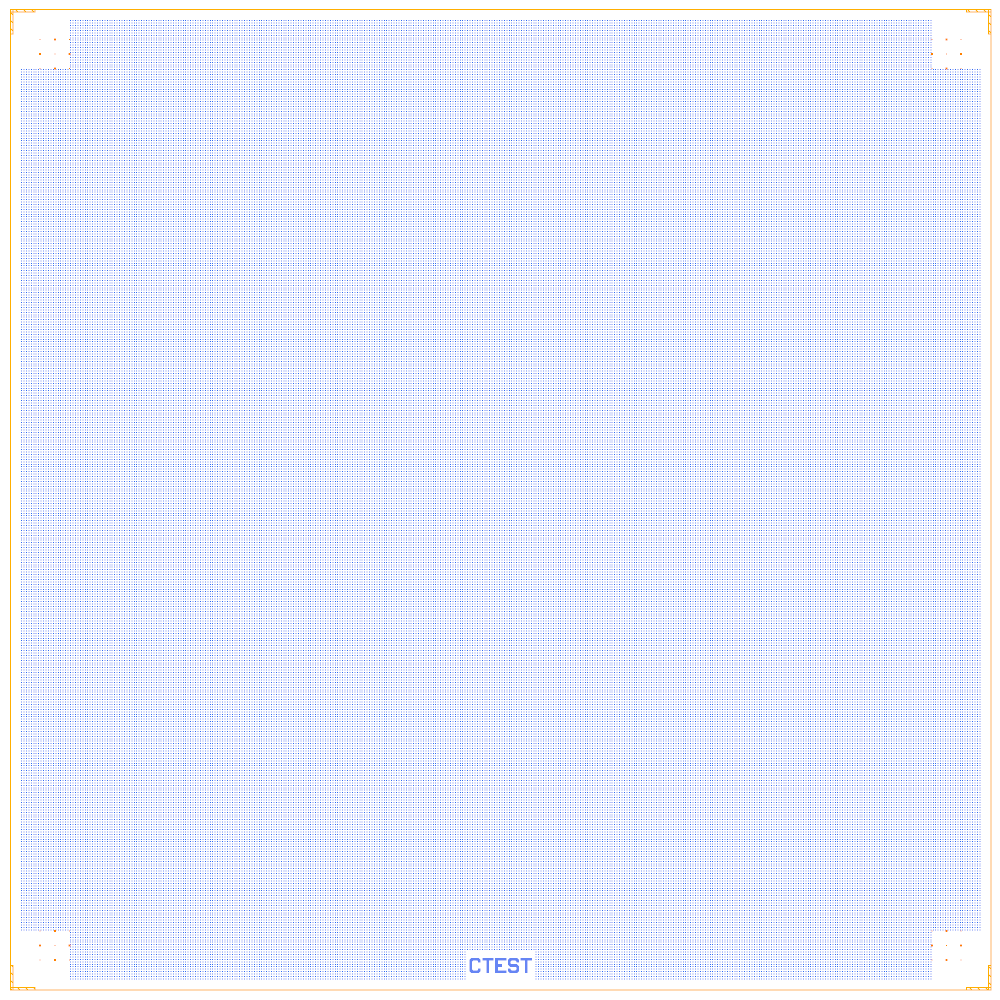

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/tsv_test/s1_die.png')

In [5]:
d = Designer("tsv_test", box=(0, 0, 10000, 10000), chip={"name_chip": "CTest", "cheese": "chip"}, live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "s1_die.png", **CHIP)

## Design 2 · The chip cell: `TsvTest`, placed once, and the save

The whole design is one instance: KQC's `TsvTest` chip PCell at the chip origin with `frames_enabled=[]`, so KQC draws
no `ChipFrame` and the Designer chip draws the Quantcore die frame (L dicing markers on 1000/0, 3 × 3 alignment
grids on 1001/0, the chip boundary on 100/0). `center_in_die` then checks that the cell's content sits centred in the
die and moves the cell if it is more than 50 µm off. The cell's content sat (−357.5, −502.5) µm off the die centre, so `center_in_die` moves the cell by (+357.5, +502.5) µm. Then the design is saved with `save_design`, which compares it with the file it replaces (the previous run's):
it should say *same design*. `tsv_test.json` is what the DRC, the fab export and `qcc` read.

The save comes before any picture of the chip, as in the v1. The picture is the whole chip; the table lists the
cell's own parameters (KQC `get_schema`) with the value this design passes where it passes one. `X0, Y0` (the cell's
origin after the centring) place the views below.

centring shift (µm): (357.5, 502.5)


**Same design as before:** `examples/designs/kqc/test_chips/tsv_test.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer tsv_test: 1 instances, 0 routes, live=False> → examples\designs\kqc\test_chips\tsv_test.json


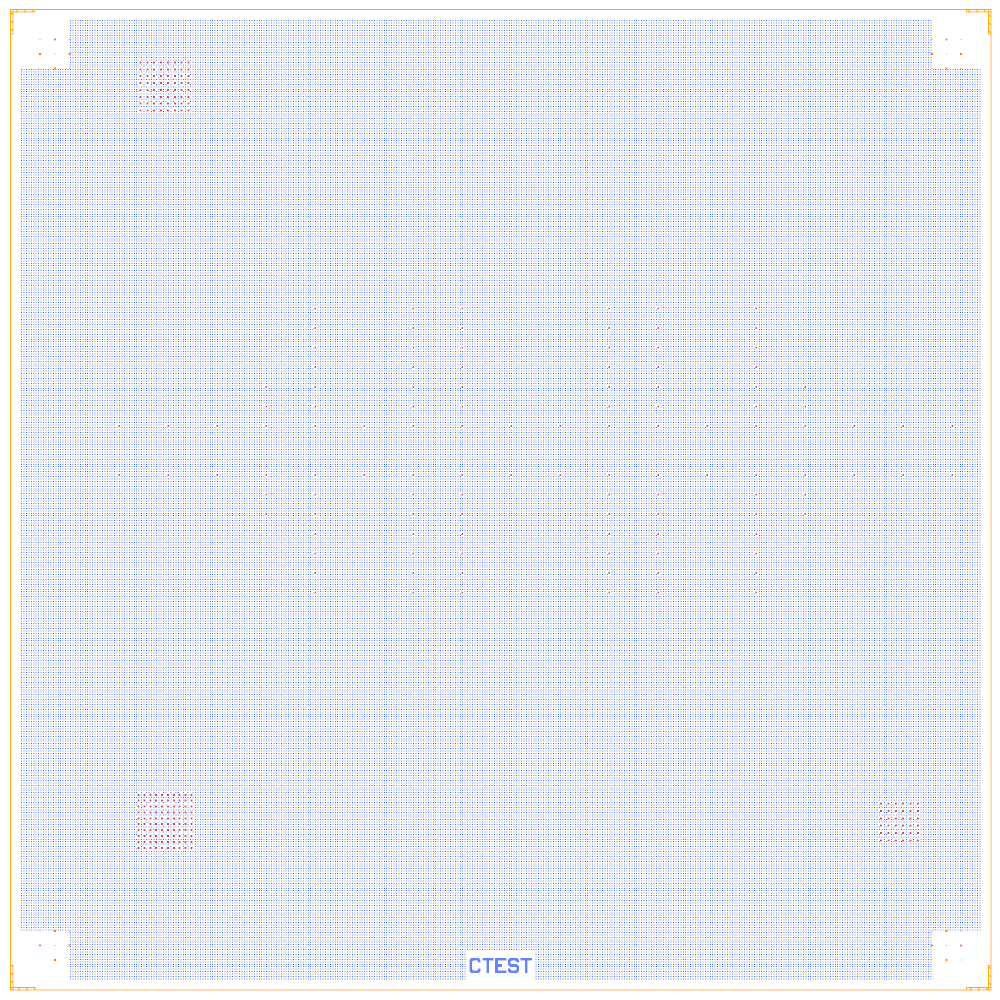

**On the chip so far:** 0 pads · 0 qubits · 1 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `CHIP`.

**`TsvTest`** parameters:

| parameter | default | this design | meaning |
|---|---|---|---|
| `array_layout` | [2, 2, 2, 6, 14, 2, 14, 14, 2, 2, 14, 14, 2, 14, 6, 2, 2, 2] | (default) | Array layout for TSV in center |
| `metrology_pitch` | 50 | (default) | Pitch in the metrology |
| `cpw_distance` | 100 | (default) | CPW Placeholder distance |
| `hor_distance` | 200 | (default) | Horizontal pitch on TSV |
| `ver_distance` | 500 | (default) | Vertical pitch on TSV |
| `a` | 10 | (default) | Width of center conductor |
| `b` | 6 | (default) | Width of gap |
| `n` | 64 | (default) | Number of points on turns |
| `r` | 100 | (default) | Turn radius |
| `margin` | 5 | (default) | Margin of the protection layer |
| `face_ids` | ['1t1', '2b1', '1b1', '2t1'] | (default) | Chip face IDs list |
| `display_name` |  | (default) | Name displayed in GUI (empty for default) |
| `protect_opposite_face` | False | (default) | Add ground grid avoidance on opposing face |
| `opposing_face_id_groups` | [['1t1', '2b1']] | (default) | Opposing face ID groups (list of lists) |
| `duplicate_face_ids` | [] | (default) | Duplicate face IDs (list of lists), where the first face of each group is copied into other faces |
| `duplicate_layers` | ['base_metal_gap', 'base_metal_gap_wo_grid', 'base_metal_add… | (default) | Layers (list), which are copied into other faces when duplicate_face_ids are given |
| `etch_opposite_face` | False | (default) | Etch avoidance shaped gap on the opposite face too |
| `etch_opposite_face_margin` | 5 | (default) | Margin of the opposite face etch shape |
| `_epr_show` | False | (default) | Show geometry related to EPR simulation, if available |
| `_epr_cross_section_cut` | False | (default) | Show EPR cross section cuts, if available |
| `_epr_counter` | 0 | (default) | Internal counter to enable EPR preview |
| `tsv_type` | Tsv Ellipse | (default) | TSV type |
| `tsv_diameter` | 10 | (default) | TSV diameter |
| `tsv_margin` | 30 | (default) | TSV margin |
| `tsv_elliptical_width` | 10 | (default) | TSV elliptical width |

In [6]:
d.add("CHIP", "TsvTest", at=(0, 0), frames_enabled=[])   # KQC chip PCell, no KQC frame
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "tsv_test.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "1_chip.png", **CHIP)
X0, Y0 = d.data["instances"]["CHIP"]["place"]["at"]   # the cell's origin (after the centring shift): the views use it
display(Markdown(pcell_params_md("TsvTest", d.data["instances"]["CHIP"]["params"])))

## Design 3 · Bond pads: none on this chip

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge
(`edge="auto"` on a pad instance). This chip has no pad instances and no launchers (the table below is empty): any probe pads belong to KQC's drawing of the cell, so the rule has nothing to place.

There are no routes either (no RF lines on this chip); the one component is the chip cell of Design 2.

In [7]:
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

## Design 4 · A view: the centre TSV pattern

At the centre a `TsvTestPattern` (KQC: a TSV fence for a CPW): 18 columns of vias 500 µm apart, column k holding
`array_layout[k]` vias (2 … 14) 200 µm apart, split above and below a 100 µm CPW placeholder (KQC adds 100 µm on each
side). The pitches are the pattern's own defaults; `TsvTest`'s `hor_distance`, `ver_distance` and `cpw_distance`
(Design 2's table) have the same values but are not passed on (KQC source). The picture zooms on six middle columns
(14, 14, 2, 2, 14, 14 vias).

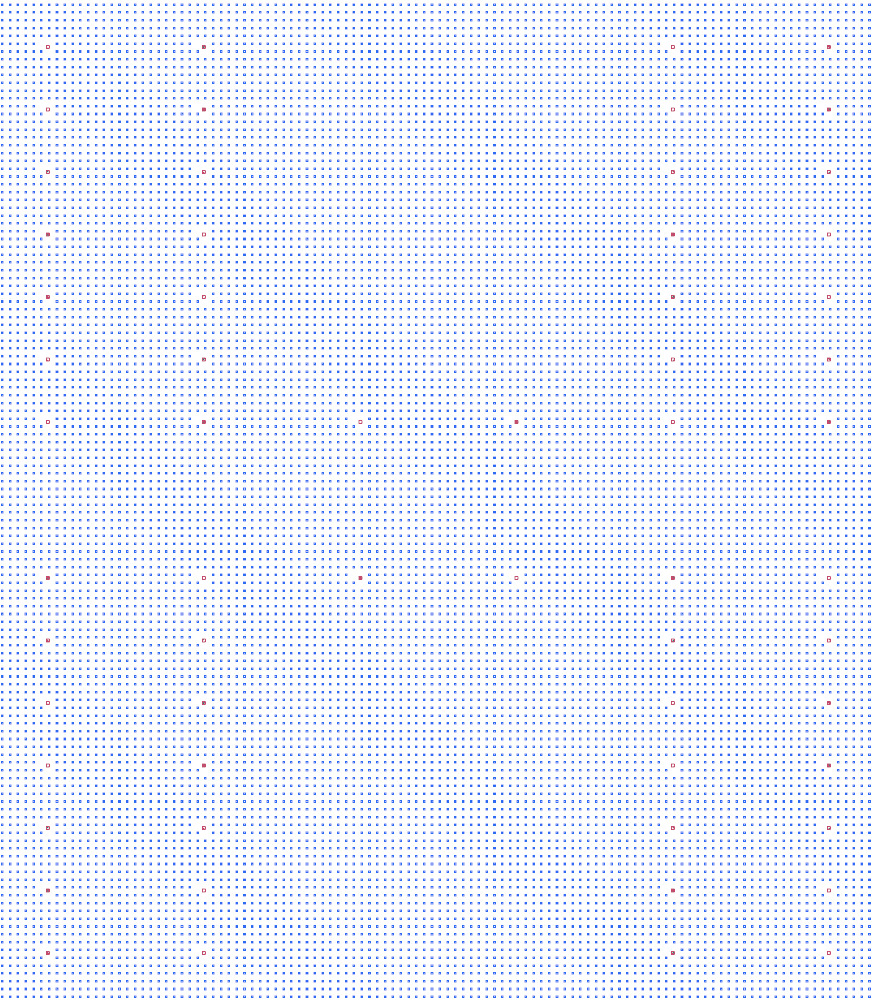

In [8]:
snap(d, STEPS / "s4_pattern.png", box=(X0 + 3600, Y0 + 3400, X0 + 6400, Y0 + 6600), size=(875, 1000), width=420);

## Design 5 · A view: a metrology array

Three square arrays of single vias for cross-sections (KQC `create_xsection`): 10 × 10 at (1250, 1250) µm with a
pitch of `metrology_pitch` + d = 60 µm, 8 × 8 at (1250, 8750) µm (50 + 2d = 70 µm) and 6 × 6 at (8750, 1250) µm
(50 + 2.5d = 75 µm), d = the via diameter (`tsv_diameter` = 10 µm for `TsvTest`; positions in the cell's frame).
The vias go to the TSV layer 700/0 in the fab export (Fab 1). The picture zooms on the 8 × 8 array (Fab 2 on the
10 × 10).

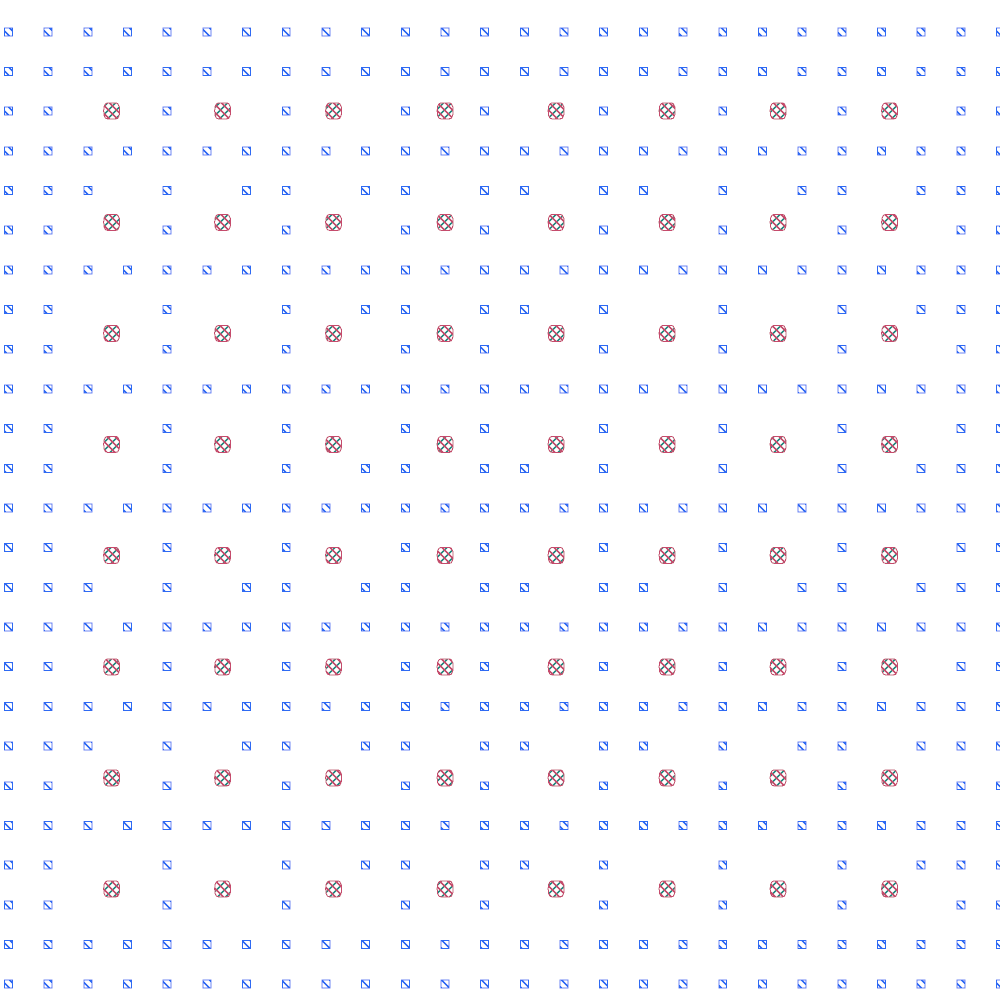

In [9]:
snap(d, STEPS / "s5_metrology.png", box=(X0 + 900, Y0 + 8400, X0 + 1530, Y0 + 9030), size=(1000, 1000), width=360);

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** 0 errors and 4 `frame_keepout` warnings: the chip cell's bounding box spans the 10 × 10 mm chip and so overlaps the four corner marker areas; nothing the cell draws sits on the dicing L's or the alignment grids (the frame-corner snapshot in Fab 2 shows it). No PDK design warning; `pdk_report` gives the PDK cheese ("PDK cheese over the whole die (drawn in the build)"), the content centred (0, 0) after the shift and no junctions.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit from the components' LOM models. No component here has one (the
chip is a process test structure), so the netlist is ground only.

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: nothing to simulate

There are no junctions, qubits or resonators, so there is nothing to simulate. The chip is measured in the process
(optical / EBL inspection, DC probing), not with microwaves.

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: nothing to export

The design has no sim groups (a process structure has nothing for a C-matrix, eigenmode or driven solve), so the
export below writes no FEM job, and the switches at the top change nothing here.

In [ ]:
jobs = export_sims(DESIGN)                       # one job per sim group: this design has none
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

# Results: no feedback loop

There is no simulated quantity and no target: `TsvTest` is a fixed test pattern. A variant is a new KQC parameter set for the cell (Design 2's table), a new design checked in the
fab view and against KQC by the XOR (Fab 2), not a knob to iterate here.

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `tsv_test.json` (saved in Design 2) is the whole design: `qcc build
examples/designs/kqc/test_chips/tsv_test.json` rebuilds `build/tsv_test.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), the through-silicon vias on 700/0 (TSV),
and the frame (100/0, 1000/0, 1001/0). In the v1 run: 1/0 934 376 polygons, 3/0 934 376, the vias 316 (700/0); cheese source `build`, 934 371 holes (KQC's grid then; the PDK cheese now drawn in the build: 150 816 holes in a probe). Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/tsv_test.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full chip; a zoom on the vias; the die frame's south-west corner (dicing L on 1000/0,
3 × 3 alignment grid on 1001/0); and the first metrology array in the **fab view** (the mask from Fab 1). The chip
boundary 100/0 is drawn as an outline.

In [ ]:
X0, Y0 = d.data["instances"]["CHIP"]["place"]["at"]   # the cell's origin (after the centring shift)
show_snapshot(d, OUT / "tsv_test.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "tsv_test_vias.png", box=(X0 + 900, Y0 + 900, X0 + 1600, Y0 + 1600), size=(800, 800), width=420)
show_snapshot(d, OUT / "tsv_test_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "tsv_test_fab.oas", OUT / "tsv_test_fab.png", box=(X0 + 1100, Y0 + 1100, X0 + 1500, Y0 + 1500), size=(1200, 1200), width=420);

**Reference: XOR with the source.** KQC's `TsvTest` built stand-alone (with KQC's own frame), XOR-ed layer by layer
with this build (`refpoints` and the `instance_names` label layer are annotation and are skipped). **The rebuild is
expected to differ** by design in the frame (KQC's ChipFrame vs the Quantcore die frame), the centring shift and the ground grid (KQC's stand-alone build has none). A
reference, not a pass/fail check.

In [ ]:
import klayout.db as kdb
from kqcircuits.chips.tsv_test import TsvTest
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
ref_top = ref.create_cell("ref")
ref_top.insert(pya.DCellInstArray(TsvTest.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "tsv_test_kqc_original.oas"))
ly = kdb.Layout()
ly.read(str(d.out))
top = ly.top_cell()
by_name = {ly.get_info(i).name: i for i in ly.layer_indexes()}
rows, total = ["| layer | XOR area (µm²) |", "|---|---|"], 0.0
for li in ref.layer_indexes():
    info = ref.get_info(li)
    a = kdb.Region(ref_top.begin_shapes_rec(li)).merged()
    if a.is_empty() or info.name in ("refpoints", "instance_names"):
        continue
    b = kdb.Region(top.begin_shapes_rec(by_name[info.name])).merged() if info.name in by_name else kdb.Region()
    x = (a ^ b).area() * ref.dbu ** 2
    total += x
    rows.append(f"| {info.name} ({info.layer}/{info.datatype}) | {x:.3g} |")
display(Markdown("\n".join(rows) + f"\n\n**Total XOR area: {total:.3g} µm²**"))
snap_file(Path("build") / "tsv_test_kqc_original.oas", OUT / "tsv_test_kqc.png", box=(-100, -100, 10100, 10100), width=420);

**From the v1 run:** the XOR (3.7 × 10⁷ µm²) is KQC's frame and the centring shift: the via layers differ by 5.75 × 10⁴ µm² on each face (the vias drawn here 357.5 / 502.5 µm away from KQC's position); the rest is the frame (base etch 8.65 × 10⁶ µm², EBL, avoidance, dicing and airbridge-marker layers).

## Summary

| | |
|---|---|
| **matches the source** | the whole `TsvTest` cell (KQC's own `build()`) |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the PDK fab layer map; the content centred (the cell moved by (+357.5, +502.5) µm); the PDK cheese round the vias instead of KQC's grid (150 816 holes in a probe; KQC's grid had 934 371 in the v1 run) |
| **not applicable** | the pad rule (no pad instances), routes, LOM, the iterate step, FEM |
| **PDK design warnings** | as listed in Check 1 |
| **FEM** | no sim groups, no jobs |
| layout | the empty die, the chip cell placed (one KQC PCell, saved there), the pad check, then 2 view(s) of its parts (the centre TSV fence and a metrology array); the saved JSON is the v1 notebook's |
| feedback | none: a fixed test pattern, no simulated quantity |
| open | the view boxes are read off the v1 run's pictures: adjust one if it misses its part |